# Treinamento YOLO11 — Auditoria de Calçadas (CPZÃO)

- **Dataset**: 95 imagens rotuladas do Mapillary com split temporal limpo (64 treino / 19 validação / 12 teste).
- **Classes (5)**: `buraco`, `faixa de pedestre`, `lixo grande`, `poste`, `vegetacao`.
- **Arquitetura**: `yolo11n.pt` (nano — otimizado para inferência mobile / edge).
- **Resolução**: `imgsz=640` (compatível com inferência em tempo real no smartphone).
- **Estudo comparativo**: **Baseline** (sem augmentation) vs **Augmentation** (Mosaic, Escala, Perspectiva, Cores e Rotação para uso manual em smartphone).

In [1]:
import subprocess, sys
from pathlib import Path

import pandas as pd
import torch
from IPython.display import Image, display
from ultralytics import YOLO

# Localizar raiz do projeto
ROOT = Path("..").resolve() if Path(".").resolve().name == "notebooks" else Path(".").resolve()
DATA = str((ROOT / "dataset" / "data.yaml").resolve())
RUNS = str((ROOT / "runs" / "main").resolve())
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Dataset config:", DATA)

PyTorch: 2.11.0+cu128
GPU: NVIDIA GeForce RTX 3060 Ti
Dataset config: F:\CP5\dataset\data.yaml


## 1. Treinamento

Comparamos:
- **Baseline**: nenhuma transformação de data augmentation.
- **Augmentation**: pacote validado na ablação, incluindo rotação suave (`degrees=10`) para compensar a inclinação da câmera em mãos de pedestres.

In [2]:
BASE_PARAMS = dict(
    data=DATA,
    epochs=80,
    patience=25,
    imgsz=640,
    batch=16,
    seed=0,
    project=RUNS,
    exist_ok=True,
)

# Baseline puro (sem augmentation)
NO_AUG = dict(
    mosaic=0.0,
    translate=0.0,
    scale=0.0,
    fliplr=0.0,
    flipud=0.0,
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,
    erasing=0.0,
    auto_augment=None,
)

# Pacote otimizado com robustez para uso móvel
AUG_PARAMS = dict(
    degrees=10.0,         # robustez contra tilt do celular
    perspective=0.0005,   # visão em perspectiva da calçada
    scale=0.5,            # variação de proximidade dos objetos
    translate=0.1,        # deslocamento espacial
    fliplr=0.5,           # espelhamento horizontal
    hsv_h=0.015,          # variação de matiz
    hsv_s=0.7,            # saturação
    hsv_v=0.4,            # brilho/iluminação
    mosaic=1.0,           # combinação 4-em-1 (crucial para dados pequenos)
    close_mosaic=10,      # desliga mosaic nas últimas 10 épocas para estabilização fina
)

def treinar(nome: str, **kwargs):
    print(f"=== Iniciando Treino: {nome} ===")
    model = YOLO("yolo11n.pt")
    model.train(name=nome, **BASE_PARAMS, **kwargs)

treinar("baseline", **NO_AUG)

=== Iniciando Treino: baseline ===
New https://pypi.org/project/ultralytics/8.4.176 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.175  Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060 Ti, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=None, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=F:\CP5\dataset\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.0, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mod

In [3]:
treinar("aug", **AUG_PARAMS)

=== Iniciando Treino: aug ===
New https://pypi.org/project/ultralytics/8.4.176 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.175  Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060 Ti, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=F:\CP5\dataset\data.yaml, degrees=10.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0

## 2. Avaliação de Métricas (Validação e Teste)

In [4]:
metrics_summary = []
for nome in ["baseline", "aug"]:
    best_weights = Path(RUNS) / nome / "weights" / "best.pt"
    model = YOLO(str(best_weights))
    for split in ["val", "test"]:
        res = model.val(
            data=DATA,
            split=split,
            imgsz=640,
            plots=(nome == "aug" and split == "test"),
            project=RUNS,
            name=f"{nome}_{split}",
            exist_ok=True,
            verbose=False,
        ).box
        metrics_summary.append({
            "modelo": nome,
            "split": split,
            "Precision": res.mp,
            "Recall": res.mr,
            "mAP@50": res.map50,
            "mAP@50-95": res.map,
        })

df_metrics = pd.DataFrame(metrics_summary)
df_metrics.round(4)

Ultralytics 8.4.175  Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060 Ti, 8192MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 2668.3784.4 MB/s, size: 298.8 KB)
val: Scanning F:\CP5\dataset\labels\val.cache... 19 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 19/19  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.2it/s 1.7s5.3s
                   all         19        121      0.196      0.163      0.142     0.0709
Speed: 0.5ms preprocess, 6.6ms inference, 0.0ms loss, 1.3ms postprocess per image
Ultralytics 8.4.175  Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060 Ti, 8192MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.10.1 ms, read: 80.320.1 MB/s, size: 334.4 KB)
val: Scanning F:\CP5\dataset\labels\test... 12 images, 1 

,modelo,split,Precision,Recall,mAP@50,mAP@50-95
0,baseline,val,0.1963,0.1625,0.1415,0.0709
1,baseline,test,0.2266,0.2219,0.1585,0.0542
2,aug,val,0.5143,0.2537,0.2699,0.1199
3,aug,test,0.3644,0.3591,0.2788,0.1027


In [5]:
# Desempenho detalhado por classe (Modelo com Augmentation no Test Set)
best_model = YOLO(str(Path(RUNS) / "aug" / "weights" / "best.pt"))
res_cls = best_model.val(
    data=DATA,
    split="test",
    imgsz=640,
    plots=False,
    verbose=False,
    project=RUNS,
    name="aug_classes_test",
    exist_ok=True,
)

df_per_class = pd.DataFrame({
    "Classe": [res_cls.names[i] for i in res_cls.box.ap_class_index],
    "mAP@50": res_cls.box.ap50,
    "mAP@50-95": res_cls.box.maps[res_cls.box.ap_class_index],
})
df_per_class.round(4)

Ultralytics 8.4.175  Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060 Ti, 8192MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 4038.0676.8 MB/s, size: 313.2 KB)
val: Scanning F:\CP5\dataset\labels\test.cache... 12 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 12/12  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 6.5it/s 0.2s
                   all         12         84      0.364      0.359      0.279      0.103
Speed: 0.2ms preprocess, 2.7ms inference, 0.0ms loss, 1.2ms postprocess per image


,Classe,mAP@50,mAP@50-95
0,buraco,0.3728,0.1110
1,faixa de pedestre,0.0051,0.0012
2,lixo grande,0.1683,0.0861
3,poste,0.5268,0.1800
4,vegetacao,0.3213,0.1352


## 3. Curvas de Treinamento e Matriz de Confusão

Curvas de Treino (Baseline vs Augmentation):


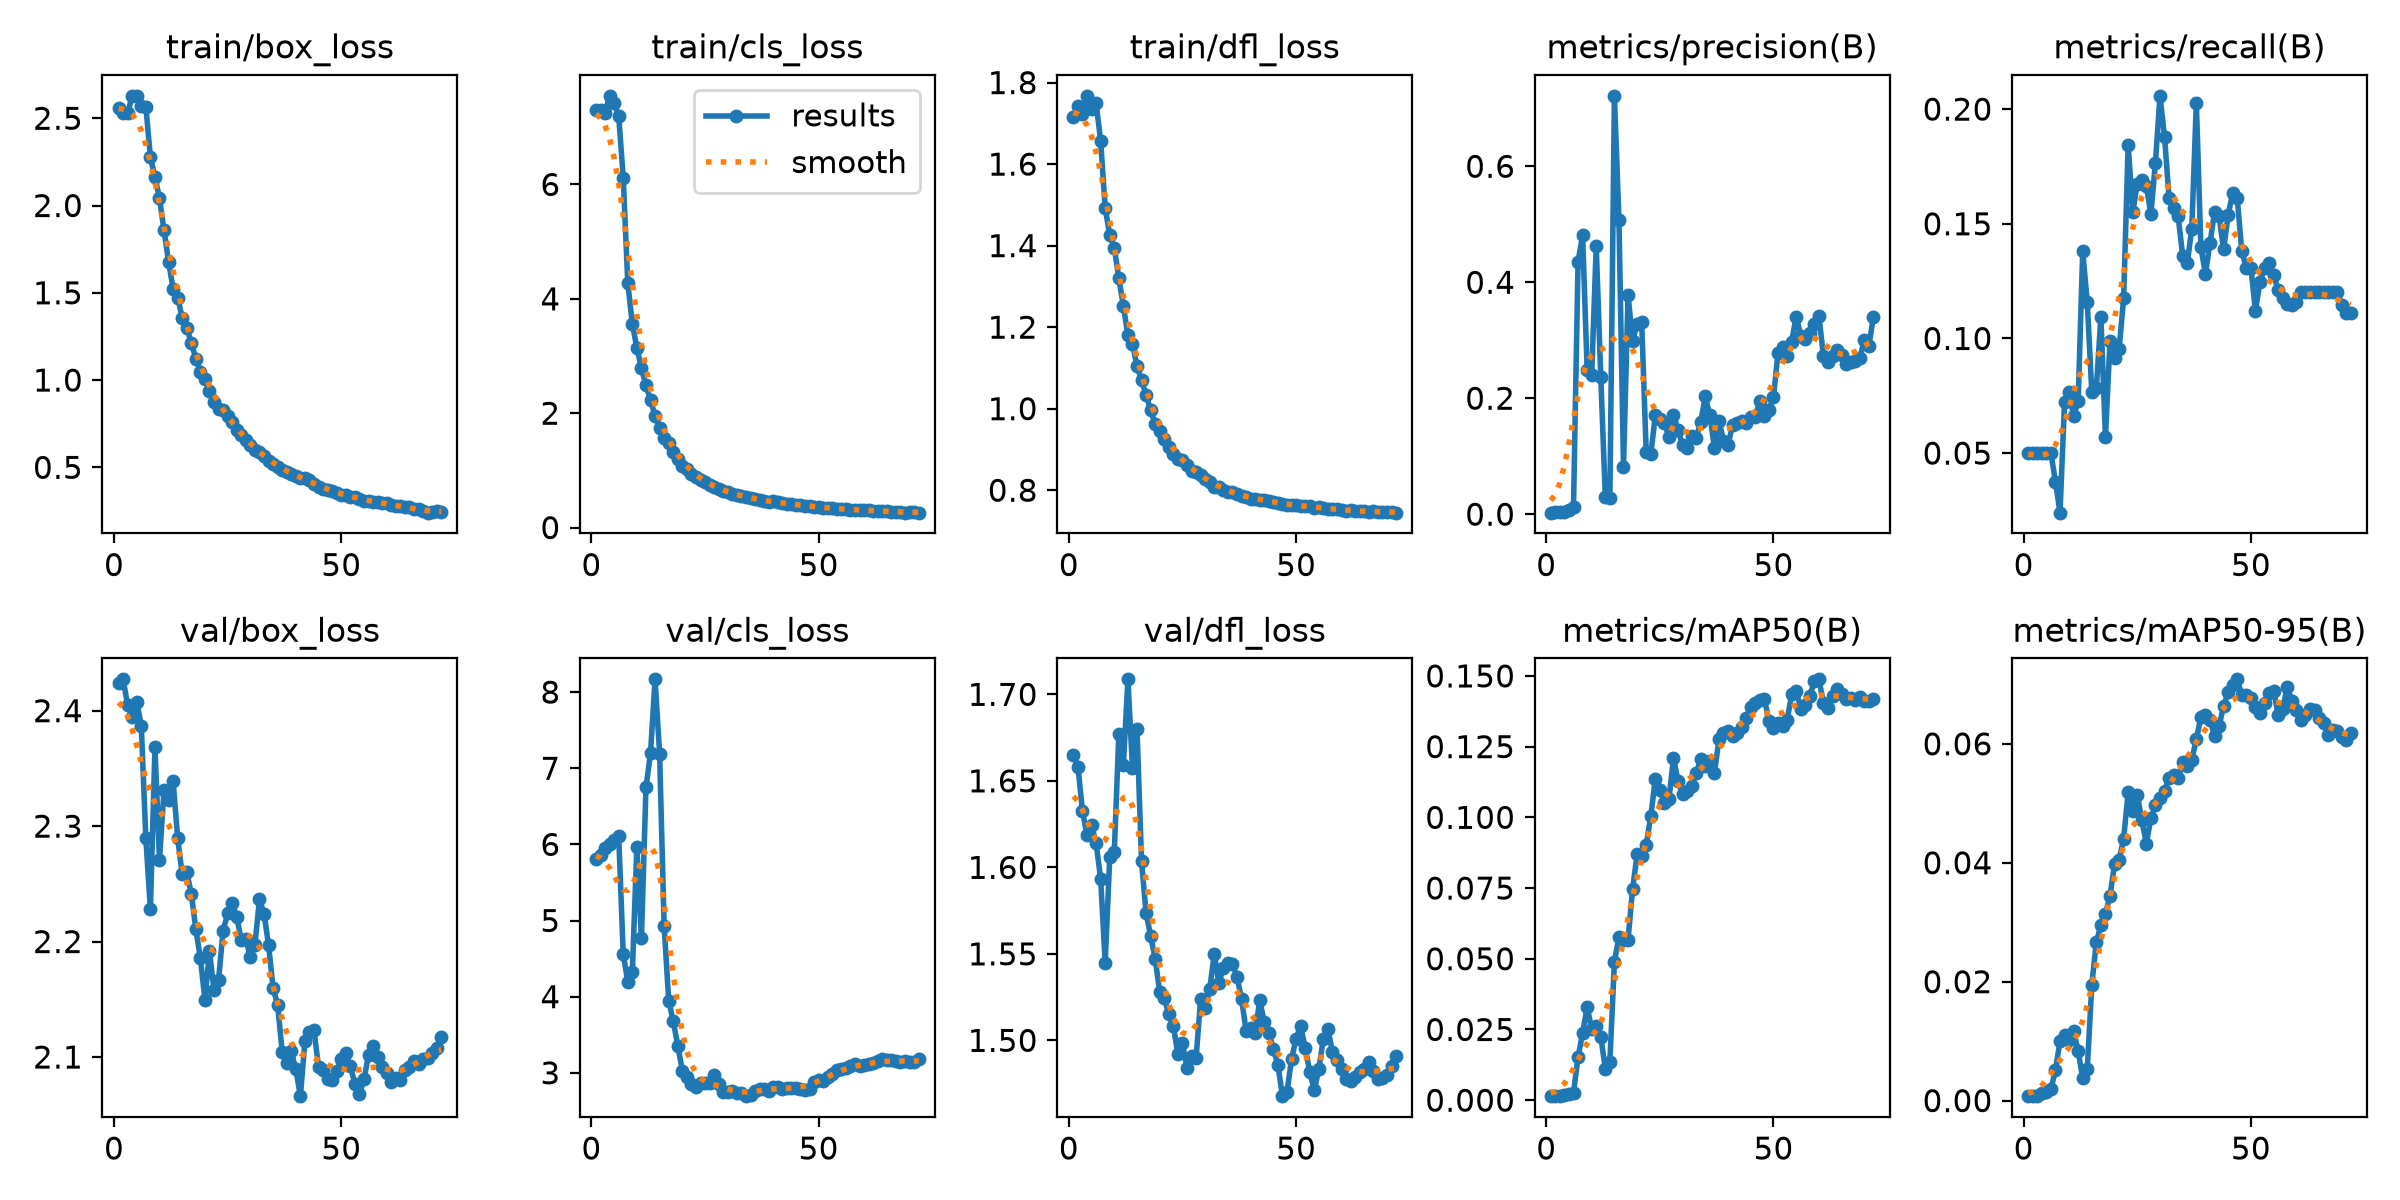

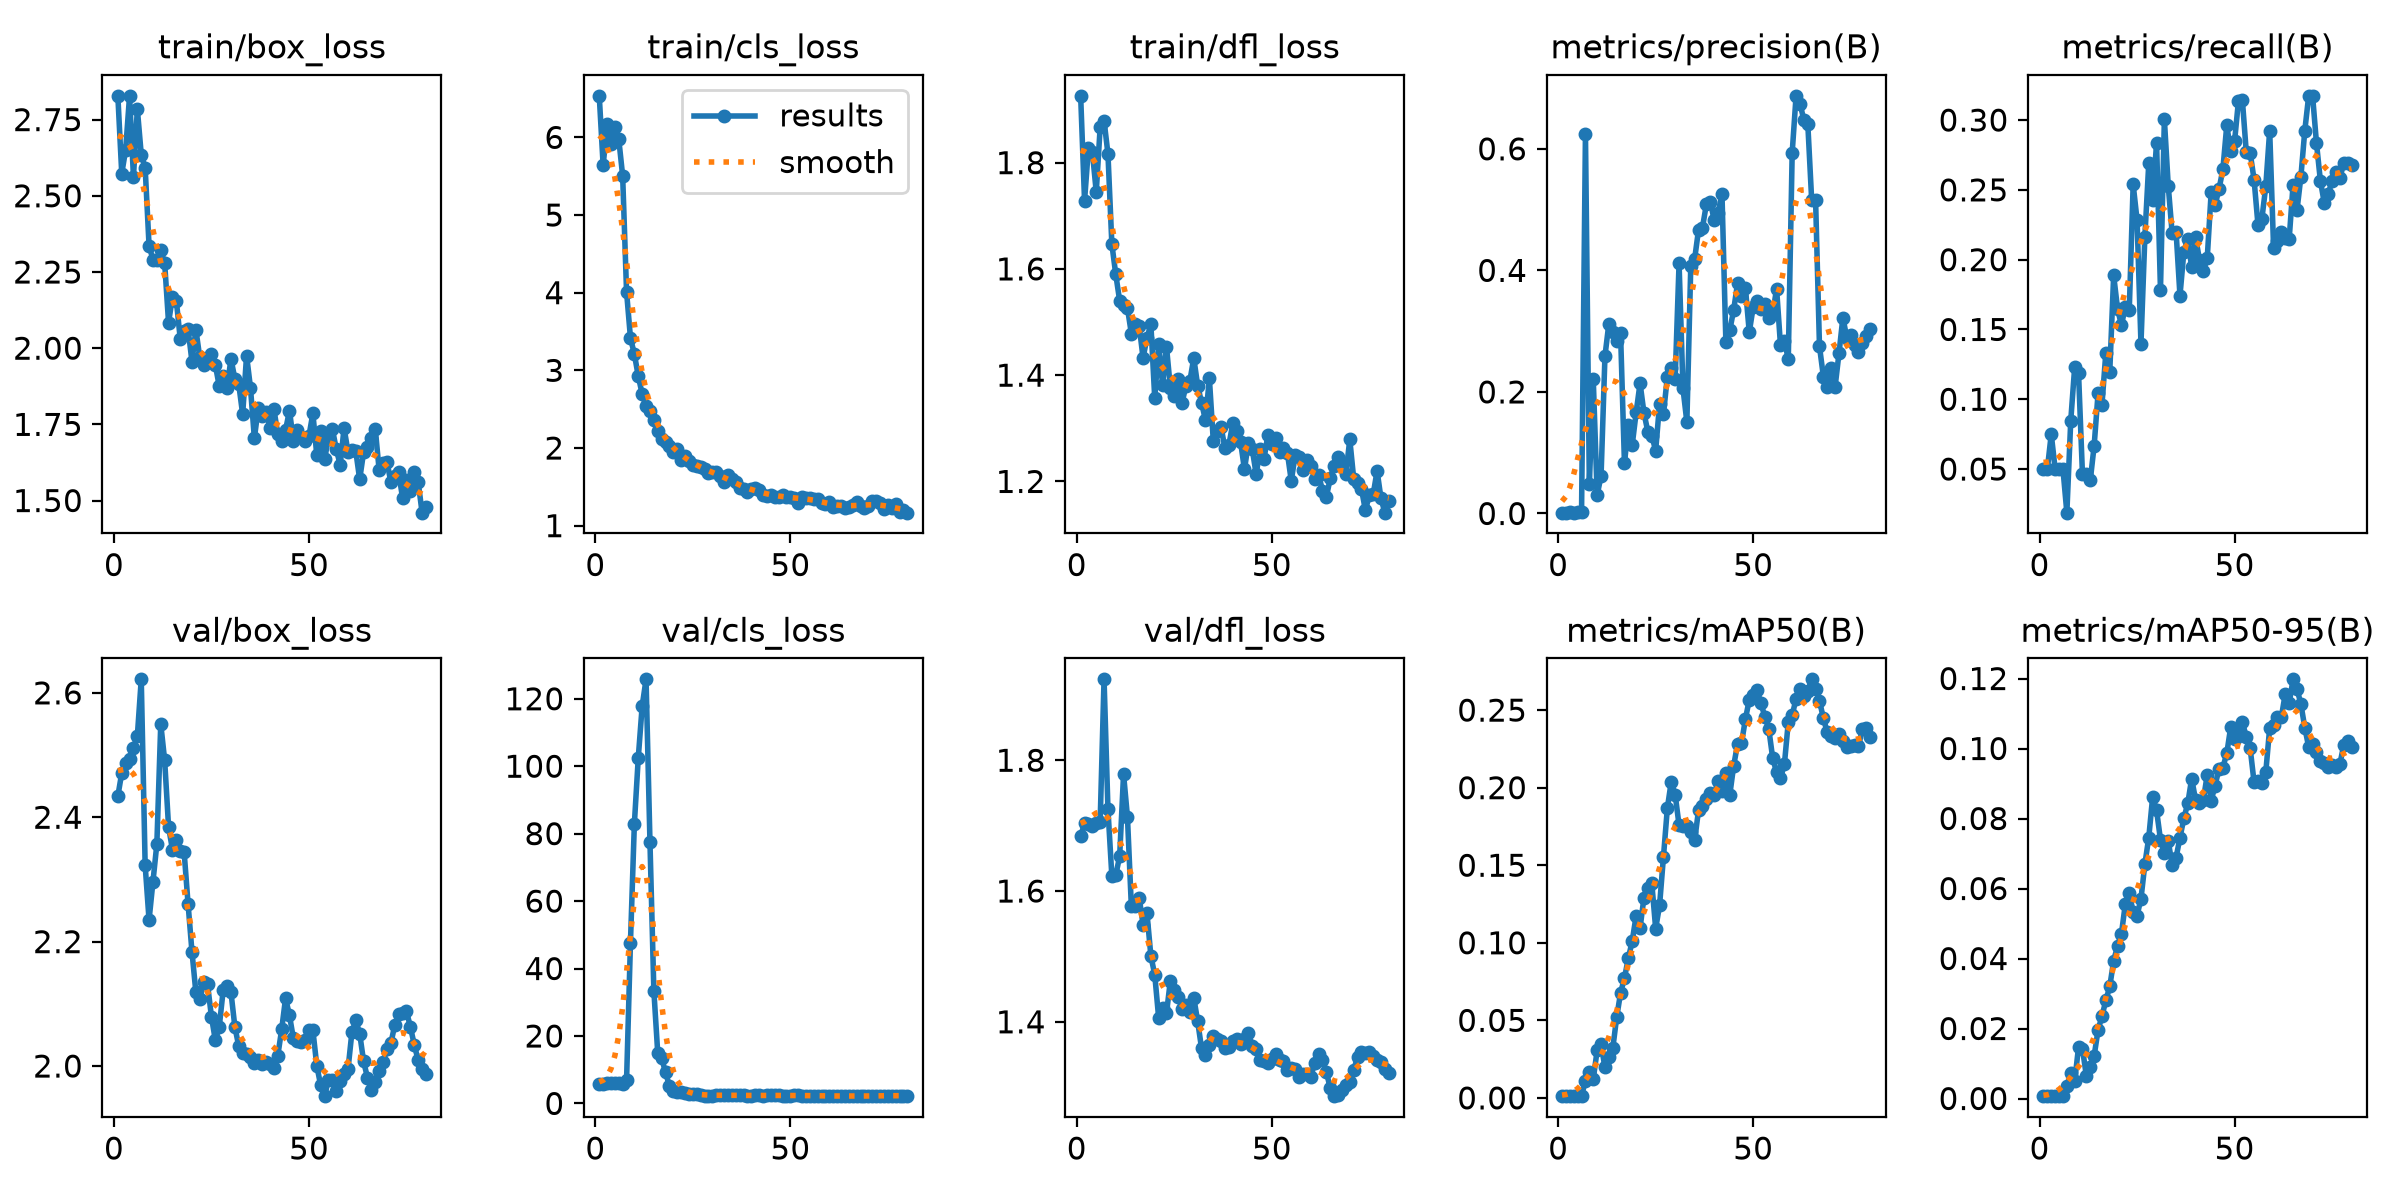

Matriz de Confusão Normalizada (Augmentation - Teste):


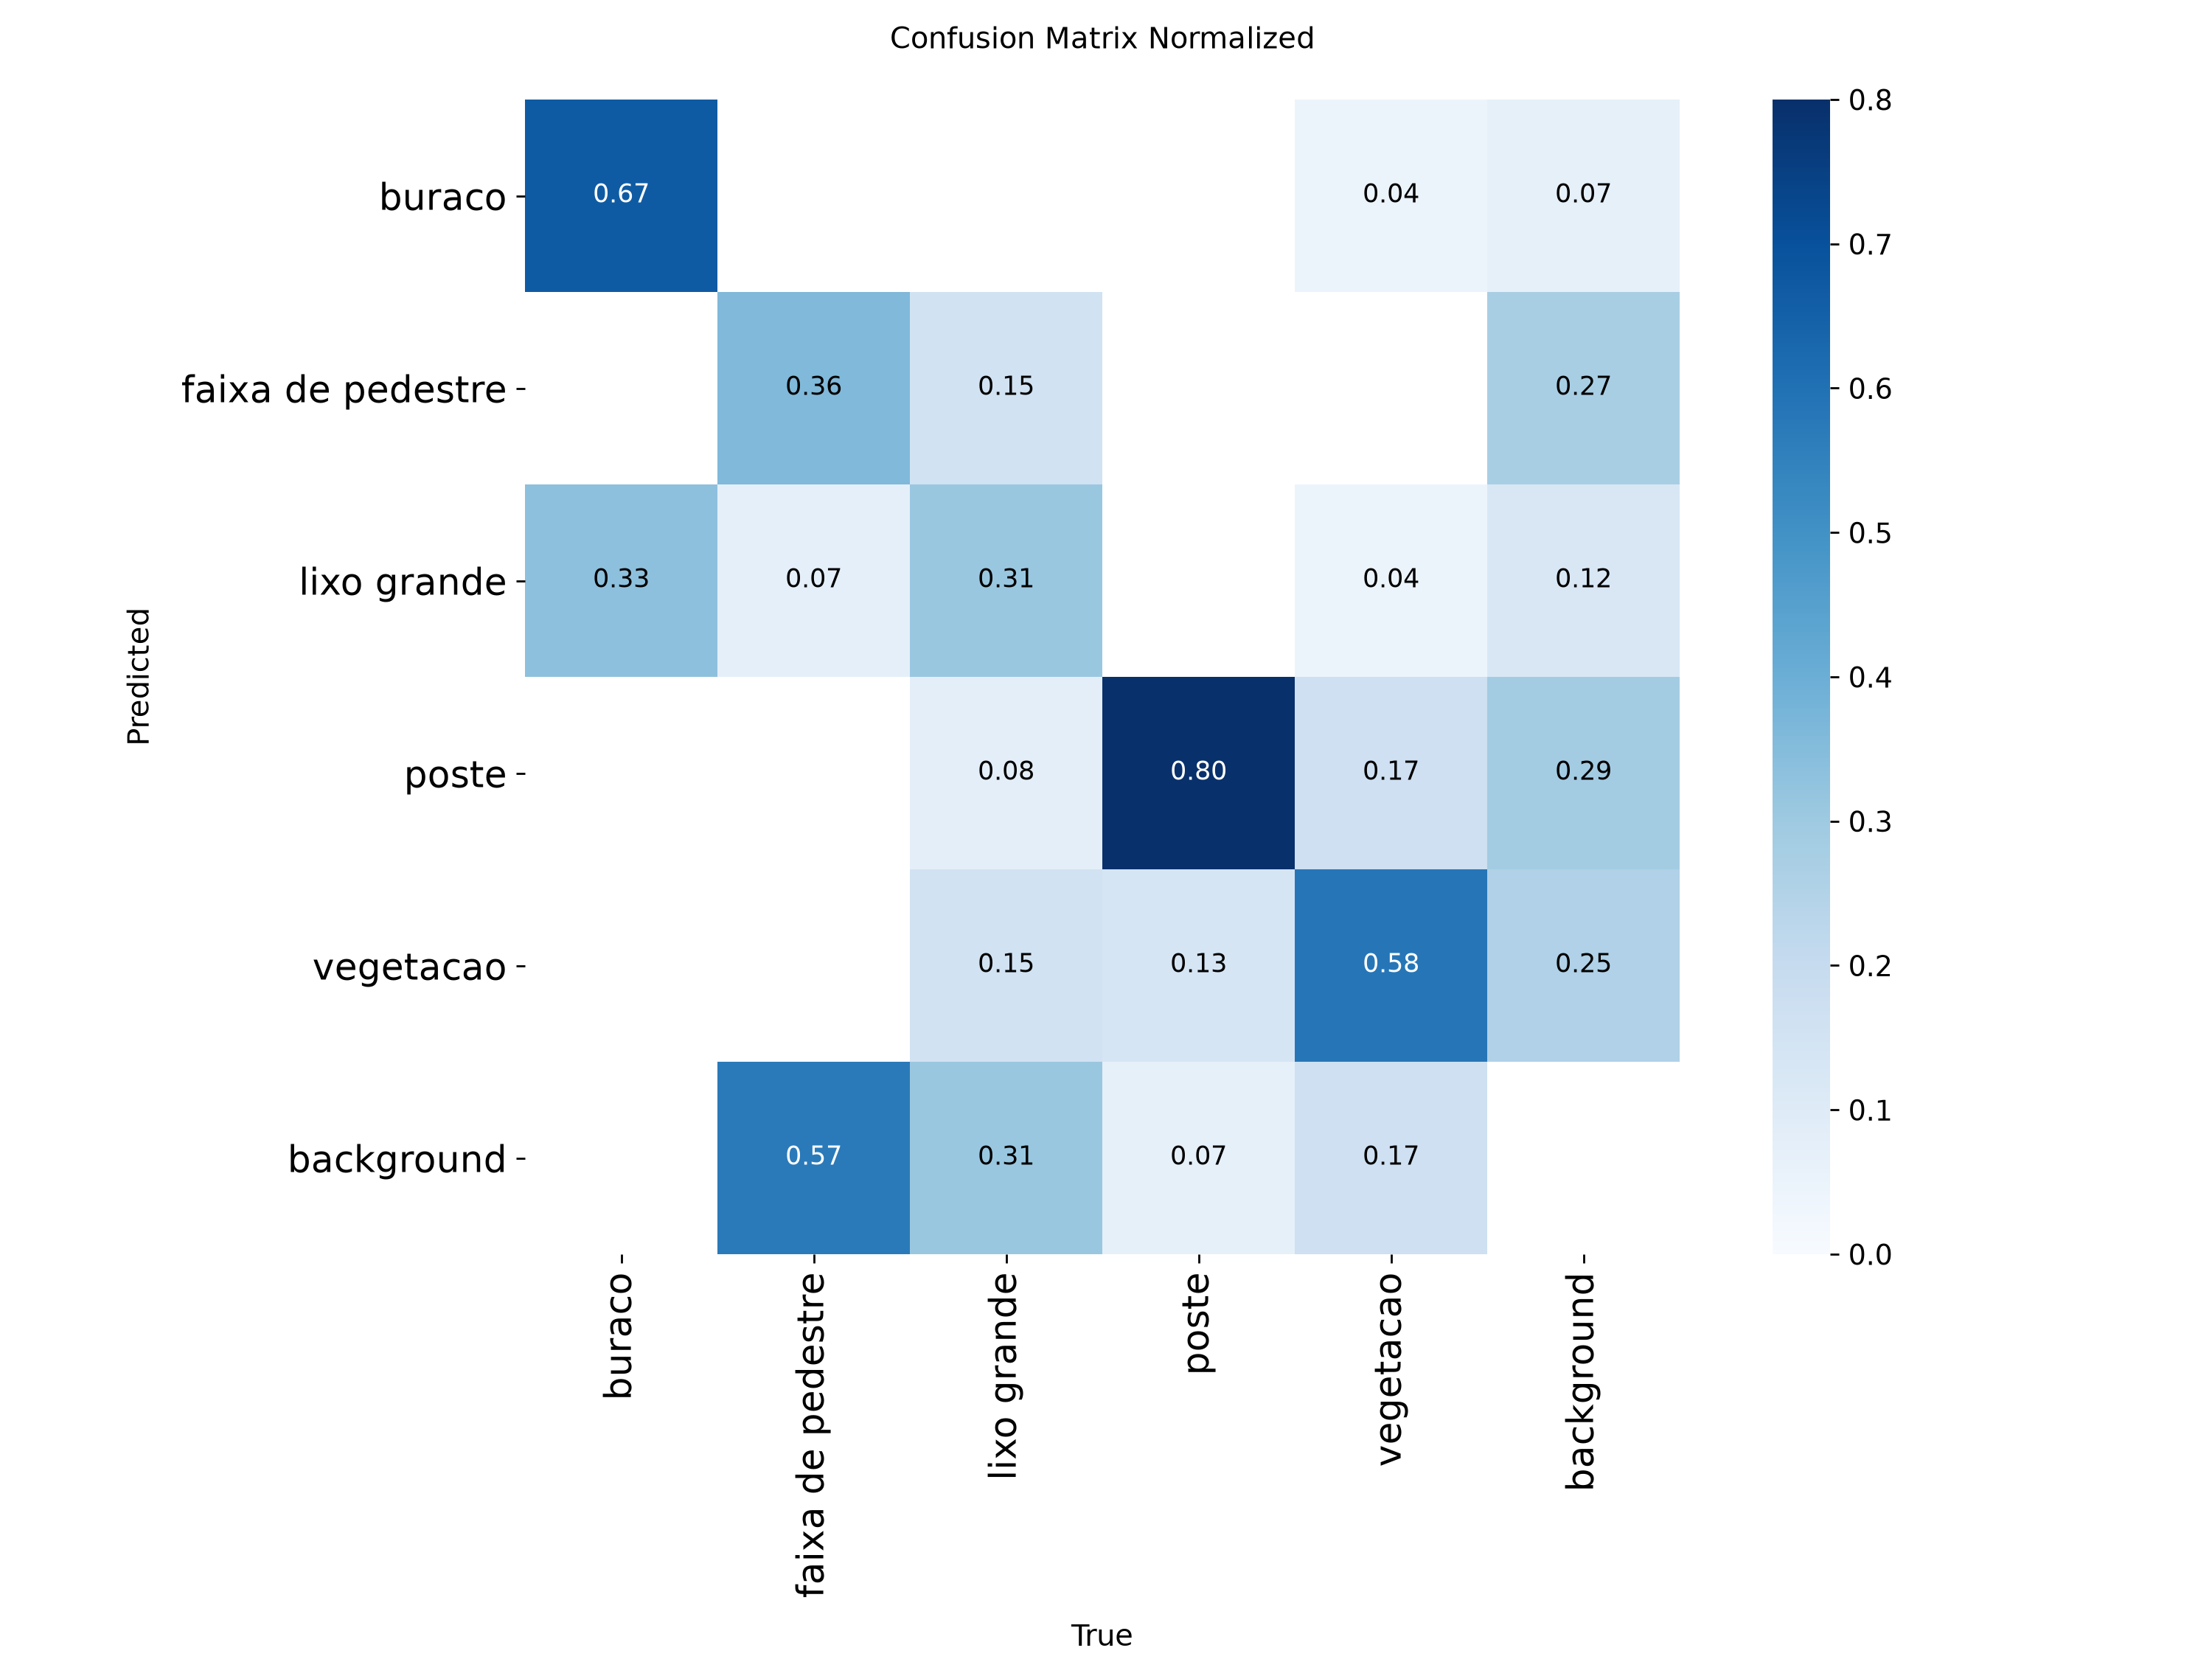

In [6]:
print("Curvas de Treino (Baseline vs Augmentation):")
display(Image(str(Path(RUNS) / "baseline" / "results.png"), width=850))
display(Image(str(Path(RUNS) / "aug" / "results.png"), width=850))

print("Matriz de Confusão Normalizada (Augmentation - Teste):")
display(Image(str(Path(RUNS) / "aug_test" / "confusion_matrix_normalized.png"), width=650))

## 4. Inferência em Imagens de Teste


image 1/12 F:\CP5\dataset\images\test\702197286288587.jpg: 384x640 2 postes, 3 vegetacaos, 6.5ms
image 2/12 F:\CP5\dataset\images\test\703116056195646.jpg: 384x640 (no detections), 8.5ms
image 3/12 F:\CP5\dataset\images\test\703184366189919.jpg: 384x640 2 vegetacaos, 7.9ms
image 4/12 F:\CP5\dataset\images\test\703255762847009.jpg: 384x640 4 postes, 2 vegetacaos, 7.2ms
image 5/12 F:\CP5\dataset\images\test\704120646092846.jpg: 384x640 1 poste, 2 vegetacaos, 9.0ms
image 6/12 F:\CP5\dataset\images\test\708770972282393.jpg: 384x640 1 lixo grande, 5 postes, 7.6ms
image 7/12 F:\CP5\dataset\images\test\717805448025207.jpg: 384x640 1 faixa de pedestre, 6 postes, 3 vegetacaos, 7.3ms
image 8/12 F:\CP5\dataset\images\test\733385326435561.jpg: 384x640 3 postes, 1 vegetacao, 7.3ms
image 9/12 F:\CP5\dataset\images\test\752114521316908.jpg: 384x640 1 poste, 6.8ms
image 10/12 F:\CP5\dataset\images\test\760108470371527.jpg: 384x640 3 faixa de pedestres, 1 poste, 7.2ms
image 11/12 F:\CP5\dataset\images

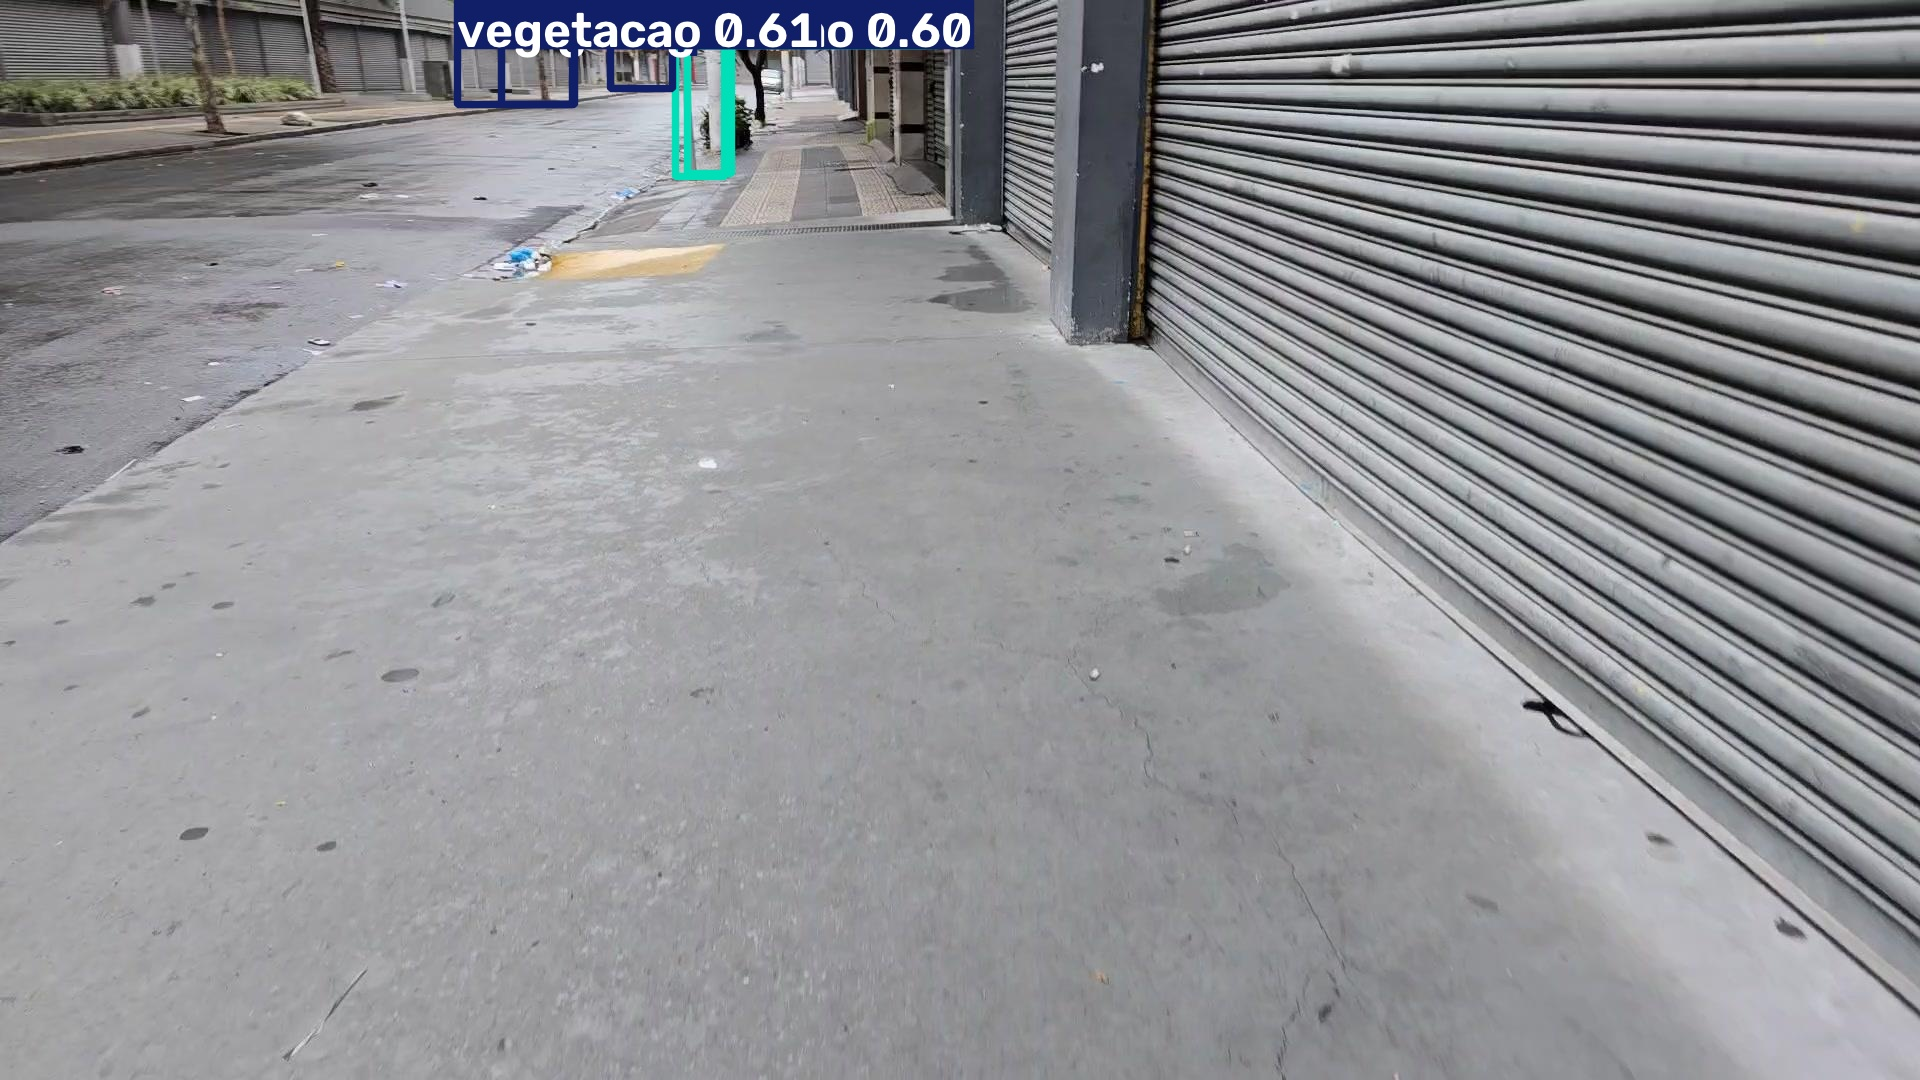

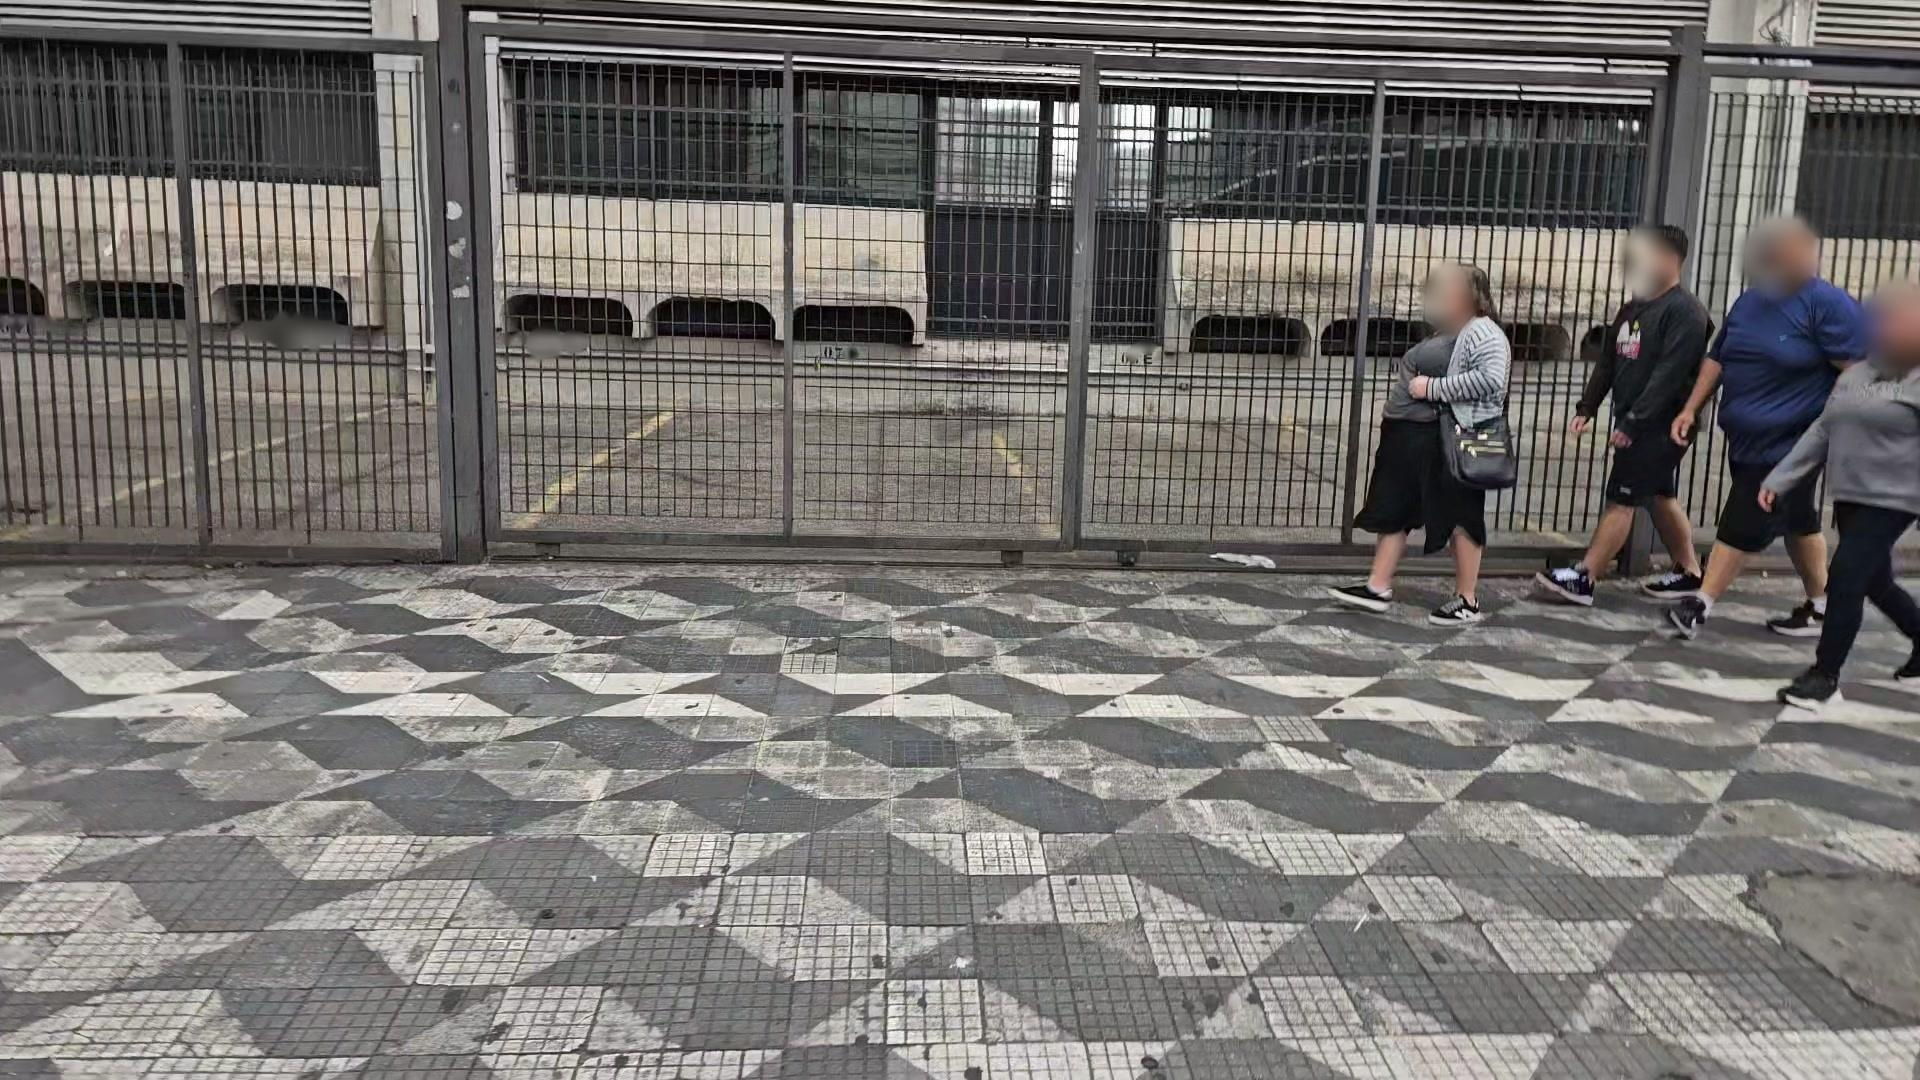

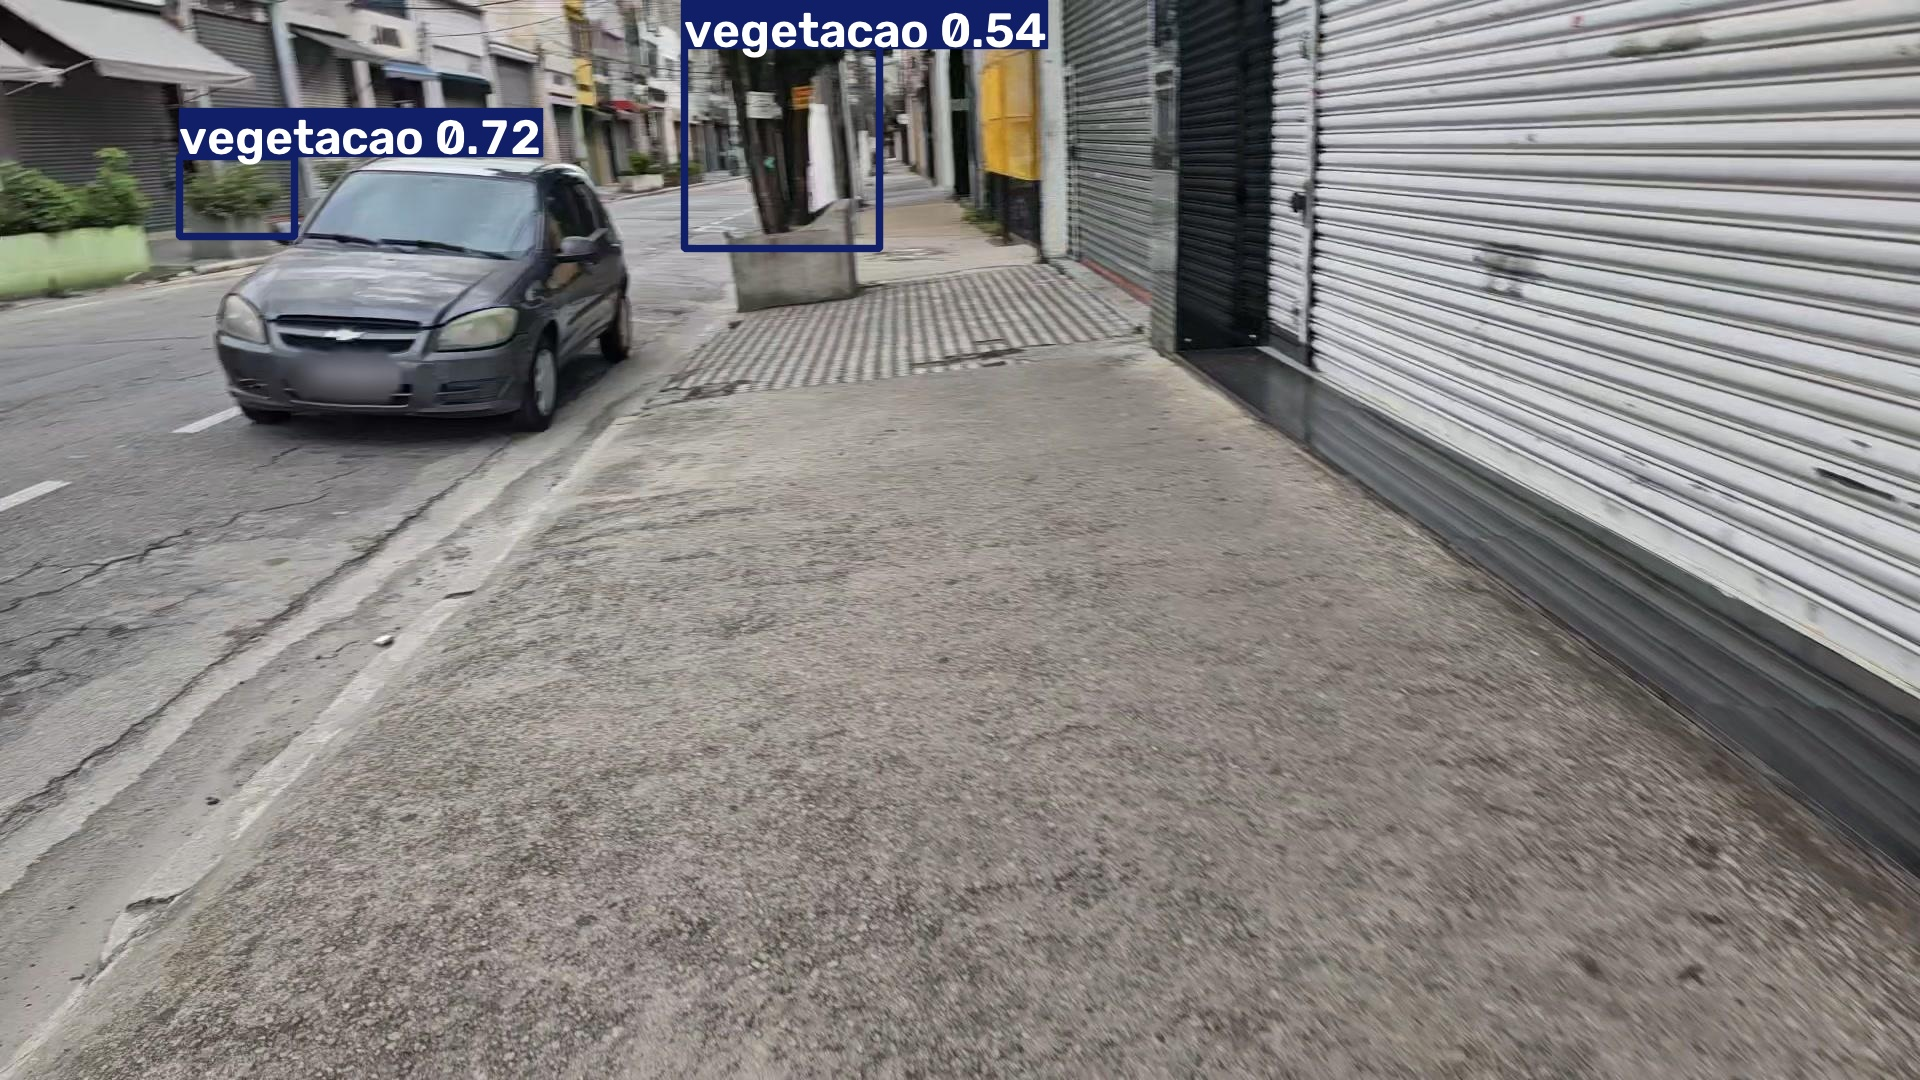

In [7]:
best_model.predict(
    source=str(ROOT / "dataset" / "images" / "test"),
    imgsz=640,
    conf=0.25,
    save=True,
    project=RUNS,
    name="predictions_test",
    exist_ok=True,
)

pred_imgs = sorted((Path(RUNS) / "predictions_test").glob("*.jpg"))
print(f"Exibindo 3 predições de teste:")
for p in pred_imgs[:3]:
    display(Image(str(p), width=850))

## 5. Exportação para Mobile (ONNX)
Exportação dos pesos finais em formato `.onnx` para integração com a PWA `yoloinferApp`.

In [9]:
import shutil

# Salvar pesos definitivos em models/
best_pt = Path(RUNS) / "aug" / "weights" / "best.pt"
final_pt = MODELS / "sidewalk-yolo11n.pt"
shutil.copy2(best_pt, final_pt)
print(f"Pesos PyTorch salvos em: {final_pt}")

# Exportar para ONNX
model_export = YOLO(str(final_pt))
exported_path = model_export.export(format="onnx", imgsz=640, simplify=True)
print(f"Modelo ONNX exportado com sucesso: {exported_path}")

Pesos PyTorch salvos em: F:\CP5\models\sidewalk-yolo11n.pt
Ultralytics 8.4.175  Python-3.12.13 torch-2.11.0+cu128 CPU (AMD Ryzen 9 7900X 12-Core Processor)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from 'F:\CP5\models\sidewalk-yolo11n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 9, 8400) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success  0.9s, saved as 'F:\CP5\models\sidewalk-yolo11n.onnx' (10.2 MB)

Export complete (1.0s)
Results saved to F:\CP5\models\sidewalk-yolo11n.onnx
Predict:         yolo predict task=detect model=F:\CP5\models\sidewalk-yolo11n.onnx imgsz=640 
Validate:        yolo val task=detect model=F:\CP5\models\sidewalk-yolo11n.onnx imgsz=640 data=F:\CP5\dataset\data.yaml  
Visualize:       https://netron.app
Modelo ONNX exportado com sucesso: F:\CP5\models\sidewalk-yolo11n.onnx
